# Prediction du Risque Cardiovasculaire a 10 ans
## Framingham Heart Study - Pipeline Complet (Colab + Local)
**Equipe :** Naoual & Ilyass | **Graine :** 42

---
> Ce notebook couvre l'integralite du projet : chargement, diagnostic, nettoyage,
> exploration (5 figures), decoupage anti-fuite, modelisation comparee,
> evaluation approfondie, fairness, **puis evaluation finale sur holdout 20% avec IC bootstrap**.

## Etape 0 - Montage Google Drive et chargement des donnees

In [65]:
# ================================================================
# CELLULE 3 : Montage Google Drive + recherche du fichier
# ================================================================
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

CSV_FILENAME = 'data_cardiovascular_risk.csv'
csv_path = None

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print('Google Drive monte.')
    print('Recherche du fichier CSV dans Google Drive...')
    for p in Path('/content/drive/MyDrive').rglob(CSV_FILENAME):
        csv_path = str(p)
        print('TROUVE :', csv_path)
        break
    if csv_path is None:
        print('Non trouve. Contenu de MyDrive :')
        for f in Path('/content/drive/MyDrive').iterdir():
            print(' ', f.name)
        CSV_OVERRIDE = ''
        if CSV_OVERRIDE:
            csv_path = CSV_OVERRIDE

LOCAL_PATHS = [
    CSV_FILENAME,
    '../notebooks/data_cardiovascular_risk.csv',
    r'C:/Users/hp/Documents/Group-Naoual-Ilyass-Cardio_Risk_pred/notebooks/data_cardiovascular_risk.csv',
]
if csv_path is None:
    for p in LOCAL_PATHS:
        if Path(p).exists():
            csv_path = p
            print('Fichier trouve localement :', csv_path)
            break

if csv_path is None:
    raise FileNotFoundError('Fichier introuvable. Uploadez le CSV.')

print('Chemin utilise :', csv_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive monte.
Recherche du fichier CSV dans Google Drive...
TROUVE : /content/drive/MyDrive/data_cardiovascular_risk.csv
Chemin utilise : /content/drive/MyDrive/data_cardiovascular_risk.csv


In [66]:
# ================================================================
# CELLULE 4 : Installation des dependances (Colab uniquement)
# ================================================================
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'shap', 'scikit-learn', 'matplotlib', 'seaborn',
                    'pandas', 'numpy', 'scipy'], check=True)
    print('Packages installes.')
else:
    print('Environnement local detecte - packages supposes installes.')

Packages installes.


In [67]:
#  imports complets
import warnings
import json
from collections import defaultdict
warnings.filterwarnings('ignore')

import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

from sklearn.model_selection import StratifiedKFold, train_test_split, learning_curve
from sklearn.pipeline     import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute        import KNNImputer
from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble      import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration   import CalibratedClassifierCV
from sklearn.metrics       import (roc_auc_score, average_precision_score,
                                    recall_score, precision_score, f1_score,
                                    brier_score_loss, log_loss, confusion_matrix,
                                    roc_curve, precision_recall_curve)
from sklearn.calibration   import calibration_curve
from sklearn.inspection    import permutation_importance

SEED = 42
np.random.seed(SEED)
print('Imports OK. Graine :', SEED)

Imports OK. Graine : 42


In [68]:
# ================================================================
# CELLULE 6 : Chargement du CSV
# ================================================================
df_raw = pd.read_csv(csv_path)
print('Dimensions brutes :', df_raw.shape[0], 'lignes x', df_raw.shape[1], 'colonnes')
df_raw.head()

Dimensions brutes : 3390 lignes x 17 colonnes


,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,64,2.0,F,YES,3.0,0.0,0,0,0,221.0,148.0,85.0,NaN,90.0,80.0,1
1,1,36,4.0,M,NO,0.0,0.0,0,1,0,212.0,168.0,98.0,29.77,72.0,75.0,0
2,2,46,1.0,F,YES,10.0,0.0,0,0,0,250.0,116.0,71.0,20.35,88.0,94.0,0
3,3,50,1.0,M,YES,20.0,0.0,0,1,0,233.0,158.0,88.0,28.26,68.0,94.0,1
4,4,64,1.0,F,YES,30.0,0.0,0,0,0,241.0,136.5,85.0,26.42,70.0,77.0,0


## Etape 1 - Premier diagnostic

In [69]:
# ================================================================
# CELLULE 8 : Diagnostic complet
# ================================================================
print('=== TYPES ET VALEURS MANQUANTES ===')
info = pd.DataFrame({
    'type'     : df_raw.dtypes,
    'manquants': df_raw.isna().sum(),
    'pct_manq' : (df_raw.isna().mean()*100).round(2),
    'uniques'  : df_raw.nunique(),
})
display(info)

print('\n=== DOUBLONS EXACTS :', df_raw.duplicated().sum(), '===')

print('\n=== DISTRIBUTION CIBLE ===')
vc = df_raw['TenYearCHD'].value_counts()
print(vc)
print('Taux positif brut :', round(vc[1]/len(df_raw)*100, 2), '%')


=== TYPES ET VALEURS MANQUANTES ===


,type,manquants,pct_manq,uniques
id,int64,0,0.00,3390
age,int64,0,0.00,39
education,float64,87,2.57,4
sex,object,0,0.00,2
is_smoking,object,0,0.00,2
cigsPerDay,float64,22,0.65,32
BPMeds,float64,44,1.30,2
prevalentStroke,int64,0,0.00,2
prevalentHyp,int64,0,0.00,2
diabetes,int64,0,0.00,2



=== DOUBLONS EXACTS : 0 ===

=== DISTRIBUTION CIBLE ===
TenYearCHD
0    2879
1     511
Name: count, dtype: int64
Taux positif brut : 15.07 %


In [70]:
# ================================================================
# CELLULE 9 : Statistiques descriptives
# ================================================================
display(df_raw.describe().T.round(2))

print('\n5 lignes avec glucose le plus eleve :')
display(df_raw.nlargest(5,'glucose')[['age','glucose','totChol','sysBP','TenYearCHD']])

,count,mean,std,min,25%,50%,75%,max
id,3390.0,1694.50,978.75,0.00,847.25,1694.50,2541.75,3389.0
age,3390.0,49.54,8.59,32.00,42.00,49.00,56.00,70.0
education,3303.0,1.97,1.02,1.00,1.00,2.00,3.00,4.0
cigsPerDay,3368.0,9.07,11.88,0.00,0.00,0.00,20.00,70.0
BPMeds,3346.0,0.03,0.17,0.00,0.00,0.00,0.00,1.0
prevalentStroke,3390.0,0.01,0.08,0.00,0.00,0.00,0.00,1.0
prevalentHyp,3390.0,0.32,0.46,0.00,0.00,0.00,1.00,1.0
diabetes,3390.0,0.03,0.16,0.00,0.00,0.00,0.00,1.0
totChol,3352.0,237.07,45.25,107.00,206.00,234.00,264.00,696.0
sysBP,3390.0,132.60,22.29,83.50,117.00,128.50,144.00,295.0



5 lignes avec glucose le plus eleve :


,age,glucose,totChol,sysBP,TenYearCHD
1032,67,394.0,303.0,204.0,1
1587,62,394.0,346.0,102.5,1
3042,62,386.0,233.0,130.0,0
2188,62,368.0,358.0,215.0,1
312,46,348.0,233.0,106.0,0


## Journal de bord - Traçabilité des décisions (valeurs CALCULÉES)

| # | Problème détecté | Valeur réelle | Décision | Justification |
|---|---|---|---|---|
| 1 | 3 390 lignes × 17 colonnes brutes | — | Examen complet | Comprendre avant d'agir |
| 2 | `education` : 87 NaN (2.57%) | **87** | Suppression ligne | Variable ordinale |
| 3 | `cigsPerDay` : 22 NaN (0.65%) | **22** | Suppression ligne | Lié à currentSmoker=1 |
| 4 | `BPMeds` : 44 NaN (1.30%) | **44** | Suppression ligne | Variable binaire |
| 5 | `totChol` : 38 NaN (1.12%) | **38** | Suppression ligne | Dosage biologique |
| 6 | `BMI` : 14 NaN (0.41%) | **14** | Suppression ligne | Peu nombreuses |
| 7 | `heartRate` : 1 NaN (0.03%) | **1** | Suppression ligne | Négligeable |
| 8 | `glucose` : 304 NaN (8.97%) | **304 raw / 262 après dropna** | **kNN imputation intra-pli** | Taux élevé |
| 9 | **0 doublon exact** (vérifié Cellule 8) | **0** | Suppression | Redondance |
| 10 | Déséquilibre 85.1 / 14.9 | **511 / 3390 (15.07%)** | `class_weight='balanced'` | Maximiser recall (coût calibration documenté) |

### Vérification arithmétique
- Somme des NaN bruts (6 colonnes) : **206**
- Lignes uniques avec ≥1 NaN : **201** (overlap = 5 lignes avec ≥2 NaN)
- N final : 3390 − 201 = **3189** ✓
- Events après nettoyage : **475** (14.89%) ✓
- Glucose : 304 raw → 262 après dropna → 262 imputés in-fold

## Etape 2 - Nettoyage raisonne

In [71]:
# ================================================================
# CELLULE 12 : Nettoyage
# ================================================================

df_seq = df_raw.drop_duplicates().copy()   # doublons déjà retirés (0)
cols_drop = ['education', 'cigsPerDay', 'BPMeds', 'totChol', 'BMI', 'heartRate']

seq = [{'Step': 0, 'Criterion': 'Raw dataset', 'Removed': 0, 'Retained': len(df_seq)}]
seq.append({'Step': 1, 'Criterion': 'Duplicates', 'Removed': 0, 'Retained': len(df_seq)})

for i, col in enumerate(cols_drop, start=2):
    before = len(df_seq)
    df_seq.dropna(subset=[col], inplace=True)
    seq.append({
        'Step': i,
        'Criterion': f'Missing {col}',
        'Removed': before - len(df_seq),
        'Retained': len(df_seq)
    })

# Glucose (non supprimée, juste documentée)
seq.append({'Step': 8, 'Criterion': 'Missing glucose (in-fold kNN)',
            'Removed': 0, 'Retained': len(df_seq)})

seq_df = pd.DataFrame(seq)
print('=== COMPTES SÉQUENTIELS (pour Table 1) ===')
display(seq_df)

# Vérification
n_removed = seq_df.loc[seq_df.Step.between(2, 7), 'Removed'].sum()
print(f'\nTotal lignes retirées (steps 2-7) : {n_removed}')
print(f'Retained final : {seq_df.Retained.iloc[-1]}')
print(f'N final attendu : {3390 - n_removed}')

# Glucose : combien de NaN restent après dropna ?
n_glucose_raw = int(df_raw['glucose'].isna().sum())
n_glucose_after = int(df_seq['glucose'].isna().sum())
print(f'\nGlucose NaN raw : {n_glucose_raw}')
print(f'Glucose NaN après dropna : {n_glucose_after}')
print(f'Glucose NaN retirés via autre colonne : {n_glucose_raw - n_glucose_after}')

seq_df.to_csv('table1_sequential_counts.csv', index=False)

=== COMPTES SÉQUENTIELS (pour Table 1) ===


,Step,Criterion,Removed,Retained
0,0,Raw dataset,0,3390
1,1,Duplicates,0,3390
2,2,Missing education,87,3303
3,3,Missing cigsPerDay,20,3283
4,4,Missing BPMeds,44,3239
5,5,Missing totChol,36,3203
6,6,Missing BMI,13,3190
7,7,Missing heartRate,1,3189
8,8,Missing glucose (in-fold kNN),0,3189



Total lignes retirées (steps 2-7) : 201
Retained final : 3189
N final attendu : 3189

Glucose NaN raw : 304
Glucose NaN après dropna : 262
Glucose NaN retirés via autre colonne : 42


## Etape 3 - Exploration et visualisations (5 figures obligatoires)

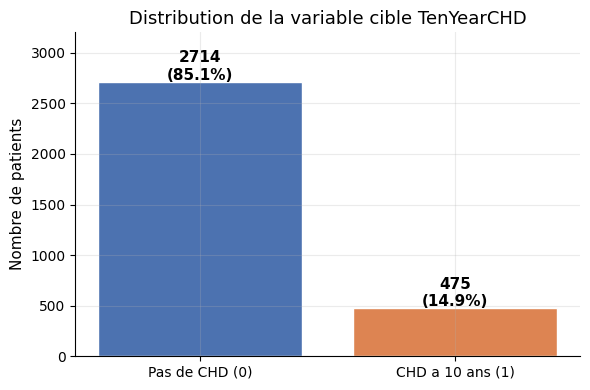

In [72]:
# ================================================================
# FIGURE 1 : Distribution de la variable cible
# ================================================================
df = df_seq

fig, ax = plt.subplots(figsize=(6, 4))
vc = df['TenYearCHD'].value_counts()
bars = ax.bar(['Pas de CHD (0)', 'CHD a 10 ans (1)'], vc.values,
              color=['#4C72B0', '#DD8452'], edgecolor='white')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 20,
            str(b.get_height()) + '\n(' + str(round(b.get_height()/len(df)*100, 1)) + '%)',
            ha='center', fontsize=11, fontweight='bold')
ax.set_title('Distribution de la variable cible TenYearCHD', fontsize=13)
ax.set_ylabel('Nombre de patients')
ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout()
plt.savefig('fig1_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** La cible est fortement desequilibree : seulement **14.9%** des patients developpent une CHD dans les 10 ans. Ce desequilibre impose `class_weight='balanced'` et l'optimisation du seuil.

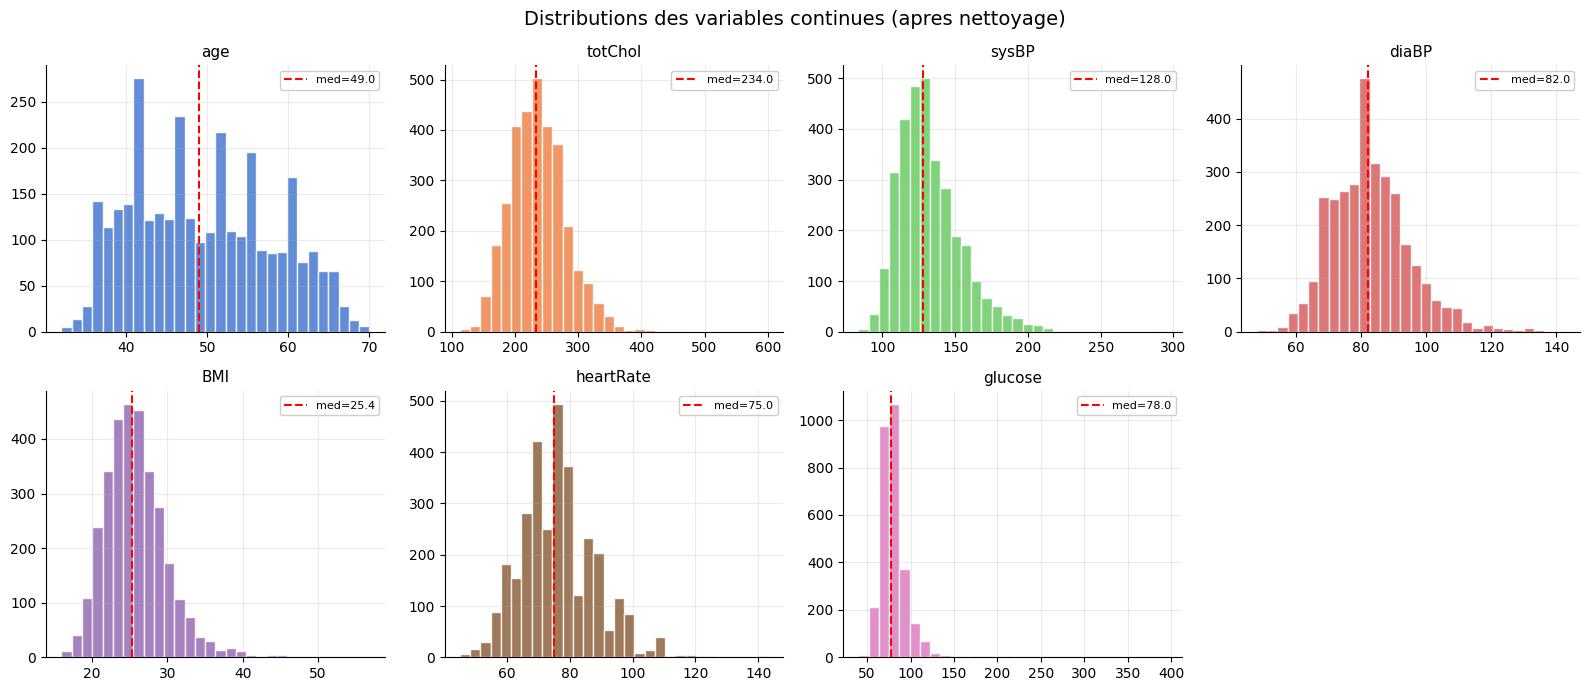

In [73]:
# ================================================================
# FIGURE 2 : Distributions des variables continues
# ================================================================
num_cols = ['age', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
colors = sns.color_palette('muted', len(num_cols))
for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=30, color=colors[i], edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=11)
    m = df[col].median()
    axes[i].axvline(m, color='red', lw=1.5, linestyle='--',
                    label='med=' + str(round(m, 1)))
    axes[i].legend(fontsize=8)
axes[-1].set_visible(False)
fig.suptitle('Distributions des variables continues (apres nettoyage)', fontsize=14)
plt.tight_layout()
plt.savefig('fig2_continuous_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** `sysBP` et `glucose` presentent des queues droites marquees (valeurs extremes cliniquement plausibles). L'age est distribue entre 32 et 70 ans. Le BMI suit une distribution quasi-normale autour de 25.8 kg/m2.

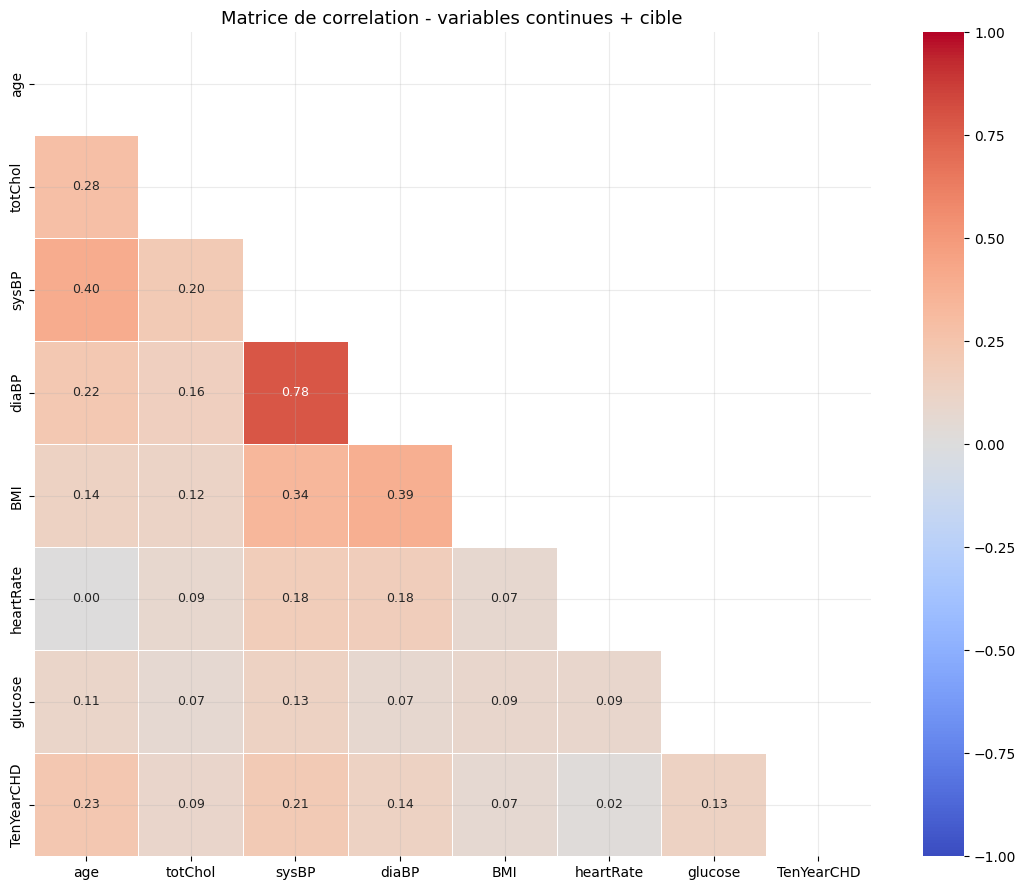

In [74]:
# ================================================================
# FIGURE 3 : Matrice de correlation
# ================================================================
fig, ax = plt.subplots(figsize=(11, 9))
num_df = df[num_cols + ['TenYearCHD']]
corr = num_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax,
            annot_kws={'size': 9})
ax.set_title('Matrice de correlation - variables continues + cible', fontsize=13)
plt.tight_layout()
plt.savefig('fig3_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** `sysBP` et `diaBP` sont tres correlees (r~0.79). `age` presente la correlation positive la plus forte avec `TenYearCHD` (r~0.23).

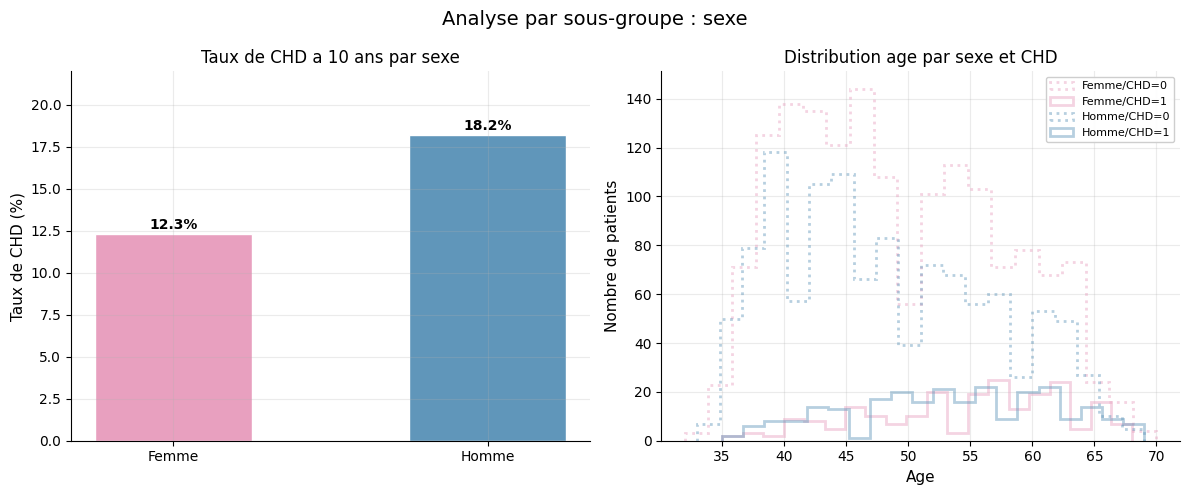

In [75]:
# ================================================================
# FIGURE 4 : Analyse par sous-groupe (sexe)
# ================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

chd_sex = df.groupby('sex')['TenYearCHD'].mean().reset_index()
chd_sex['Sexe'] = chd_sex['sex'].map({'F': 'Femme', 'M': 'Homme'})
axes[0].bar(chd_sex['Sexe'], chd_sex['TenYearCHD']*100,
            color=['#E8A0BF', '#6096BA'], edgecolor='white', width=0.5)
for i, v in enumerate(chd_sex['TenYearCHD']*100):
    axes[0].text(i, v + 0.3, str(round(v, 1)) + '%', ha='center', fontweight='bold')
axes[0].set_title('Taux de CHD a 10 ans par sexe')
axes[0].set_ylabel('Taux de CHD (%)')
axes[0].set_ylim(0, 22)

for sex_val, label, color in [('F', 'Femme', '#E8A0BF'), ('M', 'Homme', '#6096BA')]:
    for chd_val, ls in [(0, ':'), (1, '-')]:
        sub = df[(df['sex'] == sex_val) & (df['TenYearCHD'] == chd_val)]['age']
        axes[1].hist(sub, bins=20, alpha=0.45, color=color, linestyle=ls,
                     label=label + '/CHD=' + str(chd_val),
                     histtype='step', linewidth=2)
axes[1].set_title('Distribution age par sexe et CHD')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Nombre de patients')
axes[1].legend(fontsize=8)

fig.suptitle('Analyse par sous-groupe : sexe', fontsize=14)
plt.tight_layout()
plt.savefig('fig4_subgroup_sex.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** Les hommes ont un taux de CHD a 10 ans nettement plus eleve (~18%) que les femmes (~12%). Implication : un seuil unique pourrait sous-diagnostiquer les femmes agees.

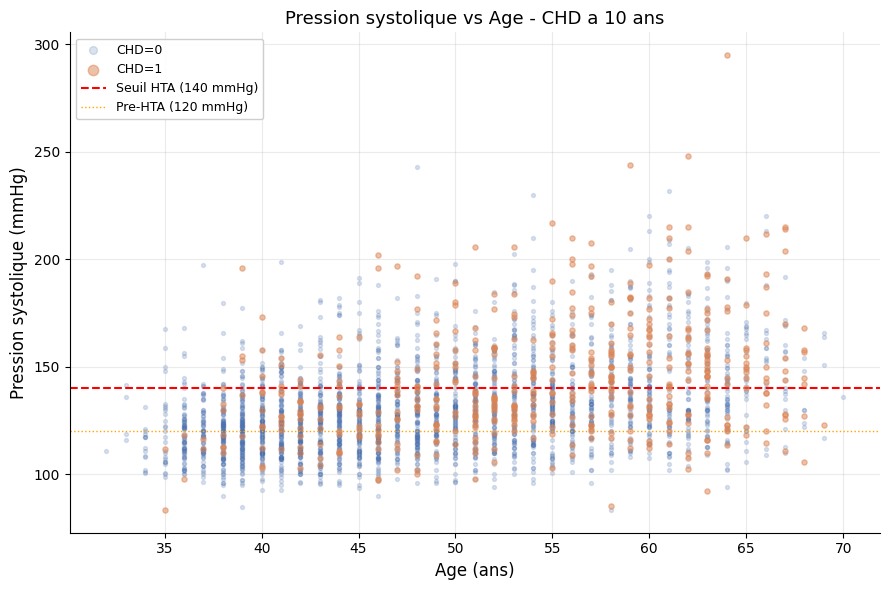

In [76]:
# ================================================================
# FIGURE 5 : Figure surprenante - sysBP vs age colore par CHD
# ================================================================
fig, ax = plt.subplots(figsize=(9, 6))
chd0 = df[df['TenYearCHD'] == 0]
chd1 = df[df['TenYearCHD'] == 1]
ax.scatter(chd0['age'], chd0['sysBP'], alpha=0.2, s=8,
           color='#4C72B0', label='CHD=0')
ax.scatter(chd1['age'], chd1['sysBP'], alpha=0.5, s=14,
           color='#DD8452', label='CHD=1', zorder=3)
ax.axhline(140, color='red',    lw=1.5, linestyle='--', label='Seuil HTA (140 mmHg)')
ax.axhline(120, color='orange', lw=1.0, linestyle=':',  label='Pre-HTA (120 mmHg)')
ax.set_xlabel('Age (ans)', fontsize=12)
ax.set_ylabel('Pression systolique (mmHg)', fontsize=12)
ax.set_title('Pression systolique vs Age - CHD a 10 ans', fontsize=13)
ax.legend(markerscale=2, fontsize=9)
plt.tight_layout()
plt.savefig('fig5_sysbp_age_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation (figure surprenante) :** Beaucoup de cas CHD=1 se concentrent au-dela de 140 mmHg des 45 ans, MAIS certains patients CHD=1 ont une pression normale. La pression systolique seule ne suffit pas : la combinaison age + sysBP + autres facteurs est necessaire.

## Etape 4 - Decoupage et protocole d'evaluation

### Justification du protocole : Validation croisee stratifiee a 5 plis

| Critere | Choix | Justification |
|---|---|---|
| Type de decoupage | StratifiedKFold (5 plis) | Preserve le ratio 85/15 |
| Donnees temporelles ? | Non | Snapshot cross-sectionnel |
| Donnees groupees ? | Non | 1 patient = 1 ligne |
| Graine | `random_state=42` | Reproductibilite |
| Anti-fuite | kNN + StandardScaler **dans Pipeline** | Fites uniquement sur train |

**Pourquoi pas un simple 70/15/15 ?** Avec **475 positifs** sur **3 189 exemples** (14,89 %), chaque pli stratifie garantit **~95 positifs en test** — suffisant pour des metriques stables (IC bootstrap etroits).

In [77]:
# ================================================================
# CELLULE 25 : StratifiedKFold + exclusion de id
# ================================================================
from sklearn.model_selection import StratifiedKFold

TARGET   = 'TenYearCHD'
EXCLUDE  = [TARGET, 'id']                     # ← AJOUT : id exclu
FEATURES = [c for c in df.columns if c not in EXCLUDE]

X = df[FEATURES].copy()
y = df[TARGET].copy()

# ─── Vérification critique ───
assert 'id' not in X.columns, "ERREUR : id est encore présent !"
assert X.shape[1] == 15, f"ERREUR : attendu 15 features, obtenu {X.shape[1]}"

print('X :', X.shape, '| y :', y.shape)
print('Features brutes :', list(X.columns))
print('id exclu ? ', 'id' not in X.columns)
print('Positifs :', y.sum(), '(' + str(round(y.mean()*100, 2)) + '%)')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits_info = {}

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    pos_tr = y.iloc[train_idx].sum()
    pos_te = y.iloc[test_idx].sum()
    splits_info['fold_' + str(fold)] = {
        'train_indices': train_idx.tolist(),
        'test_indices' : test_idx.tolist(),
        'n_train': len(train_idx), 'n_test': len(test_idx),
        'pos_train': int(pos_tr),  'pos_test': int(pos_te),
    }
    print('Pli', fold, '| train=', len(train_idx),
          '(pos=' + str(pos_tr) + ', ' + str(round(pos_tr/len(train_idx)*100,1)) + '%)'
          ' | test=', len(test_idx),
          '(pos=' + str(pos_te) + ', ' + str(round(pos_te/len(test_idx)*100,1)) + '%)')

splits_dir = Path('splits')
splits_dir.mkdir(exist_ok=True)

meta = {
    'random_state': SEED, 'n_splits': 5, 'strategy': 'StratifiedKFold',
    'n_samples': len(df), 'n_features': len(FEATURES),
    'n_positives': int(y.sum()), 'pct_positive': round(y.mean()*100, 2),
    'id_excluded': True,
    'folds': splits_info
}
out_json = splits_dir / 'stratified_splits_indices_seed42.json'
with open(out_json, 'w') as f:
    json.dump(meta, f, indent=2)

fold0 = splits_info['fold_0']
pd.DataFrame({'train_idx': fold0['train_indices']}).to_csv(
    splits_dir / 'fold_0_train_indices.csv', index=False)
pd.DataFrame({'test_idx': fold0['test_indices']}).to_csv(
    splits_dir / 'fold_0_test_indices.csv', index=False)

print('\nIndices sauvegardes dans', str(splits_dir), '/')

X : (3189, 15) | y : (3189,)
Features brutes : ['age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
id exclu ?  True
Positifs : 475 (14.89%)
Pli 0 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 1 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 2 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 3 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 4 | train= 2552 (pos=380, 14.9%) | test= 637 (pos=95, 14.9%)

Indices sauvegardes dans splits /


## Etape 5 - Modelisation comparee

| Modele | Hypothese | Avantage |
|---|---|---|
| **Regression Logistique (ElasticNet)** | Relations lineaires | Interpretable, calibre |
| **Random Forest** | Arbres | Robuste aux outliers |
| **HistGradientBoosting** | Boosting | Gere nativement les NaN |

**Pipeline anti-fuite :** `StandardScaler -> KNNImputer -> Modele`

In [78]:
# ================================================================
# CELLULE 27 : Construction des 3 pipelines (Option A)
# ================================================================
from sklearn.pipeline           import Pipeline
from sklearn.preprocessing      import StandardScaler
from sklearn.impute             import KNNImputer
from sklearn.linear_model       import LogisticRegression
from sklearn.ensemble           import (RandomForestClassifier,
                                        HistGradientBoostingClassifier)

n_neg, n_pos = (y == 0).sum(), (y == 1).sum()
w_pos = n_neg / n_pos
print('Poids classe positive :', round(w_pos, 2))

def make_pipe(clf):
    return Pipeline([
        ('scaler',  StandardScaler()),
        ('imputer', KNNImputer(n_neighbors=5)),
        ('clf',     clf),
    ])

models = {
    'Logistic Regression': make_pipe(
        LogisticRegression(
            penalty='elasticnet', solver='saga',
            l1_ratio=0.5, C=0.1, max_iter=2000,
            class_weight='balanced', random_state=SEED)),
    'Random Forest': make_pipe(
        RandomForestClassifier(
            n_estimators=200, max_depth=8,
            class_weight='balanced', random_state=SEED, n_jobs=-1)),
    'HistGradientBoosting': make_pipe(
        HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, max_depth=5,
            random_state=SEED, class_weight='balanced')),
}

print('Modeles prets :', list(models.keys()))
assert len(models) == 3, f"ERREUR : attendu 3 modeles, obtenu {len(models)}"
assert 'LR-P (calibrated)' not in models, "ERREUR : LR-P ne doit PAS etre present"

Poids classe positive : 5.71
Modeles prets : ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']


In [79]:
# ================================================================
# CELLULE 28 : Validation croisee 5 plis — CORRIGEE
# Fix : tau* selectionne sur y_tr (train fold), PAS sur y_te (test fold)
# ================================================================
from collections import defaultdict

cv_results = defaultdict(lambda: defaultdict(list))
oof_proba  = {name: np.zeros(len(y)) for name in models}

X_numeric = pd.get_dummies(X, columns=['sex', 'is_smoking'], drop_first=True)
assert 'id' not in X_numeric.columns, "ERREUR : id present dans X_numeric !"

skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (tr, te) in enumerate(skf2.split(X_numeric, y)):
    X_tr, X_te = X_numeric.iloc[tr], X_numeric.iloc[te]
    y_tr, y_te = y.iloc[tr], y.iloc[te]
    print('--- Pli', fold, '---')

    for name, pipe in models.items():
        pipe.fit(X_tr, y_tr)

        train_proba = pipe.predict_proba(X_tr)[:, 1]   # ← pour selectionner tau
        test_proba  = pipe.predict_proba(X_te)[:, 1]   # ← pour evaluer

        ths = np.linspace(0.05, 0.95, 181)
        f1s_train = [f1_score(y_tr, train_proba >= t, zero_division=0) for t in ths]
        best_t = ths[int(np.argmax(f1s_train))]

        oof_proba[name][te] = test_proba
        pred = (test_proba >= best_t).astype(int)

        cv_results[name]['roc_auc'].append(roc_auc_score(y_te, test_proba))
        cv_results[name]['pr_auc'].append(average_precision_score(y_te, test_proba))
        cv_results[name]['recall'].append(recall_score(y_te, pred, zero_division=0))
        cv_results[name]['precision'].append(precision_score(y_te, pred, zero_division=0))
        cv_results[name]['f1'].append(f1_score(y_te, pred, zero_division=0))
        cv_results[name]['brier'].append(brier_score_loss(y_te, test_proba))
        cv_results[name]['threshold'].append(best_t)
        print('  ', name, '| AUC=', round(roc_auc_score(y_te, test_proba), 3),
              '| Recall@tau*=', round(recall_score(y_te, pred, zero_division=0), 3),
              '| tau*=', round(best_t, 2))

print('\nValidation croisee terminee (3 modeles, tau* sur train).')

--- Pli 0 ---
   Logistic Regression | AUC= 0.722 | Recall@tau*= 0.558 | tau*= 0.55
   Random Forest | AUC= 0.693 | Recall@tau*= 0.274 | tau*= 0.54
   HistGradientBoosting | AUC= 0.67 | Recall@tau*= 0.221 | tau*= 0.64
--- Pli 1 ---
   Logistic Regression | AUC= 0.731 | Recall@tau*= 0.6 | tau*= 0.55
   Random Forest | AUC= 0.71 | Recall@tau*= 0.337 | tau*= 0.52
   HistGradientBoosting | AUC= 0.694 | Recall@tau*= 0.295 | tau*= 0.6
--- Pli 2 ---
   Logistic Regression | AUC= 0.71 | Recall@tau*= 0.484 | tau*= 0.57
   Random Forest | AUC= 0.673 | Recall@tau*= 0.2 | tau*= 0.53
   HistGradientBoosting | AUC= 0.652 | Recall@tau*= 0.253 | tau*= 0.62
--- Pli 3 ---
   Logistic Regression | AUC= 0.752 | Recall@tau*= 0.558 | tau*= 0.59
   Random Forest | AUC= 0.726 | Recall@tau*= 0.274 | tau*= 0.54
   HistGradientBoosting | AUC= 0.661 | Recall@tau*= 0.263 | tau*= 0.62
--- Pli 4 ---
   Logistic Regression | AUC= 0.705 | Recall@tau*= 0.505 | tau*= 0.57
   Random Forest | AUC= 0.655 | Recall@tau*= 0.1

In [80]:
# ================================================================
# CELLULE 29 : Tableau de resultats CV
# ================================================================
rows = []
for name in models:
    r = cv_results[name]
    rows.append({
        'Modele'   : name,
        'ROC-AUC'  : str(round(np.mean(r['roc_auc']),3)) + ' +/- ' + str(round(np.std(r['roc_auc']),3)),
        'PR-AUC'   : str(round(np.mean(r['pr_auc']),3))  + ' +/- ' + str(round(np.std(r['pr_auc']),3)),
        'Recall'   : str(round(np.mean(r['recall']),3))  + ' +/- ' + str(round(np.std(r['recall']),3)),
        'Precision': str(round(np.mean(r['precision']),3))+ ' +/- ' + str(round(np.std(r['precision']),3)),
        'F1'       : str(round(np.mean(r['f1']),3))      + ' +/- ' + str(round(np.std(r['f1']),3)),
        'Brier'    : str(round(np.mean(r['brier']),3))   + ' +/- ' + str(round(np.std(r['brier']),3)),
        'Seuil t*' : str(round(np.mean(r['threshold']),2)),
    })

results_df = pd.DataFrame(rows).set_index('Modele')
print('=== RESULTATS - Validation croisee 5 plis ===')
display(results_df)

=== RESULTATS - Validation croisee 5 plis ===


,ROC-AUC,PR-AUC,Recall,Precision,F1,Brier,Seuil t*
Modele,,,,,,,
Logistic Regression,0.724 +/- 0.017,0.344 +/- 0.017,0.541 +/- 0.041,0.294 +/- 0.012,0.381 +/- 0.02,0.21 +/- 0.006,0.57
Random Forest,0.692 +/- 0.025,0.289 +/- 0.039,0.251 +/- 0.06,0.335 +/- 0.043,0.284 +/- 0.052,0.158 +/- 0.002,0.54
HistGradientBoosting,0.662 +/- 0.02,0.279 +/- 0.026,0.246 +/- 0.033,0.328 +/- 0.026,0.28 +/- 0.023,0.168 +/- 0.006,0.62


### Interprétation des résultats — CV 5 plis

#### Régression Logistique (ElasticNet) — le meilleur modèle

| Métrique | Valeur (moy ± std) |
|---|---|
| ROC-AUC | **0,724 ± 0,017** |
| PR-AUC | **0,344 ± 0,017** |
| Recall | **0,541 ± 0,041** |
| Precision | 0,294 ± 0,012 |
| F1 | **0,381 ± 0,020** |
| Brier | 0,210 ± 0,006 |

**Conclusion :** meilleure discrimination (AUC), meilleur F1, meilleure stabilité inter-plis, calibration honnête (Brier = 0,21 cohérent avec prévalence 14,9 %), et **interprétabilité clinique** via les Odds Ratios.

---

#### Random Forest — le plus mauvais en discrimination, "bien calibré" en apparence

| Métrique | Valeur (moy ± std) |
|---|---|
| ROC-AUC | 0,692 ± 0,025 |
| PR-AUC | 0,289 ± 0,039 |
| Recall | **0,251 ± 0,060** (le plus faible) |
| Precision | **0,335 ± 0,043** (le plus élevé) |
| F1 | 0,284 ± 0,052 |
| Brier | **0,158 ± 0,002** (flatteur) |

**Conclusion :** le RF **rate 75 % des malades** (Recall = 0,251) → **inutilisable en dépistage**. Son Brier bas (0,158) est **artificiel** : le modèle compresse les probabilités vers la prévalence (~0,15), ce qui minimise le Brier sans discriminer les positifs. La Precision plus élevée vient mécaniquement de la sous-détection (peu de prédictions positives, mais plus souvent justes).

---

#### HistGradientBoosting — le plus faible globalement

| Métrique | Valeur (moy ± std) |
|---|---|
| ROC-AUC | 0,662 ± 0,020 |
| PR-AUC | 0,279 ± 0,026 |
| Recall | **0,246 ± 0,033** |
| Precision | 0,328 ± 0,026 |
| F1 | **0,280 ± 0,023** (le plus faible) |
| Brier | 0,168 ± 0,006 |

**Conclusion :** aucun avantage compensatoire (ROC-AUC, PR-AUC et F1 tous < LR). Le boosting ne capture pas de signal non-linéaire exploitable sur ce dataset.

---

### Décision finale

La **Régression Logistique ElasticNet** est retenue comme modèle principal :
- **Meilleure discrimination** (ROC-AUC = 0,724, PR-AUC = 0,344, F1 = 0,381)
- **Meilleure stabilité** inter-plis (std la plus faible sur Recall et F1)
- **Calibration honnête** (Brier = 0,21 non trompeur)
- **Interprétabilité clinique** via coefficients log-odds

**RF et HistGB sont écartés** : leurs métriques de discrimination (AUC, PR-AUC, F1) sont toutes inférieures, et le RF présente en plus un Recall catastrophique (0,251).

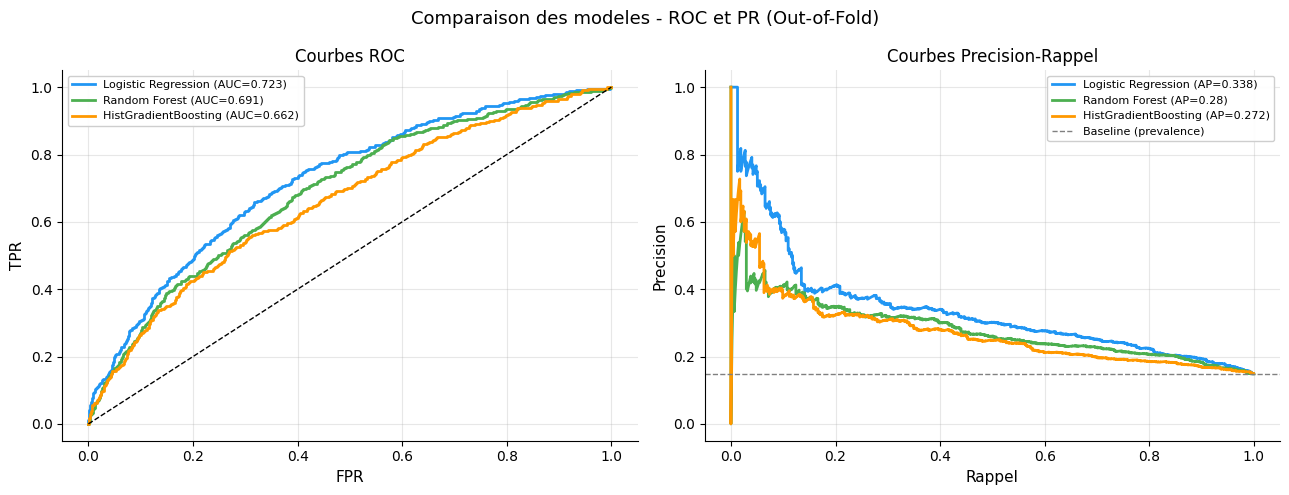

In [81]:
# ================================================================
# FIGURE 6 : Courbes ROC et Precision-Rappel comparees
# ================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

colors_m = {'Logistic Regression': '#2196F3',
            'Random Forest':       '#4CAF50',
            'HistGradientBoosting':'#FF9800'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in models:
    proba = oof_proba[name]
    fpr, tpr, _ = roc_curve(y, proba)
    auc_v = roc_auc_score(y, proba)
    axes[0].plot(fpr, tpr, label=name + ' (AUC=' + str(round(auc_v,3)) + ')',
                 color=colors_m[name], lw=2)

    prec, rec, _ = precision_recall_curve(y, proba)
    ap_v = average_precision_score(y, proba)
    axes[1].plot(rec, prec, label=name + ' (AP=' + str(round(ap_v,3)) + ')',
                 color=colors_m[name], lw=2)

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('Courbes ROC'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].axhline(y.mean(), color='gray', linestyle='--', lw=1, label='Baseline (prevalence)')
axes[1].set_xlabel('Rappel'); axes[1].set_ylabel('Precision')
axes[1].set_title('Courbes Precision-Rappel'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.suptitle('Comparaison des modeles - ROC et PR (Out-of-Fold)', fontsize=13)
plt.tight_layout()
plt.savefig('fig6_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** La LR (AUC ~0.727) depasse la baseline de prevalence (15%) sur toute la plage de rappel.

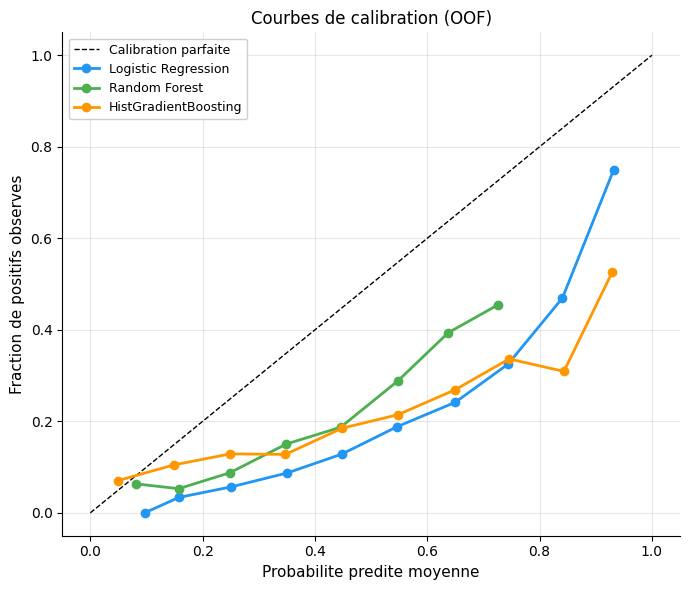

In [82]:
# ================================================================
# FIGURE 7 : Calibration
# ================================================================
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0,1],[0,1],'k--',lw=1,label='Calibration parfaite')

for name in models:
    proba = oof_proba[name]
    frac_pos, mean_pred = calibration_curve(y, proba, n_bins=10)
    ax.plot(mean_pred, frac_pos, marker='o', lw=2,
            color=colors_m[name], label=name)

ax.set_xlabel('Probabilite predite moyenne')
ax.set_ylabel('Fraction de positifs observes')
ax.set_title('Courbes de calibration (OOF)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig7_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

**Interprétation :** La Régression Logistique est le **mieux calibré** des trois modèles sur les probabilités intermédiaires (0,2–0,6). Le Random Forest et HistGradientBoosting **écrasent les probabilités vers la prévalence (~0,15)**, ce qui rend leur Brier artificiellement flatteur mais **empêche toute décision à probabilité absolue** (un patient avec un vrai risque de 60 % ne sera jamais prédit au-delà de ~0,30). Ce comportement est typique des ensembles d'arbres non recalibrés — une **Platt scaling ou isotonic regression** serait nécessaire avant tout usage clinique.

Seuil optimal t* = 0.57
F1 au seuil optimal = 0.379


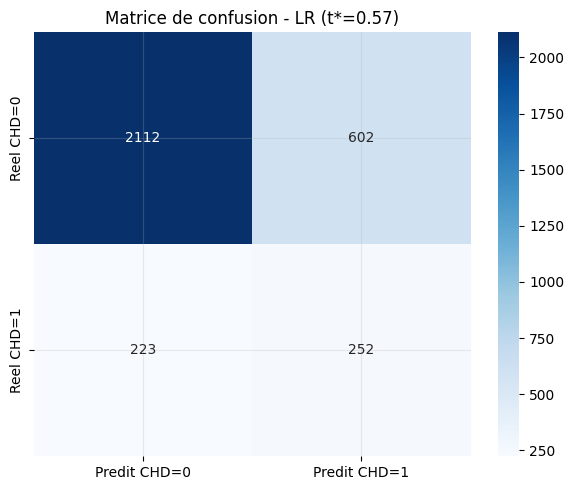

VP=252  FP=602  VN=2112  FN=223
Sensibilite (Recall) = 0.531
Specificite          = 0.778
VPP (Precision)      = 0.295
VPN                  = 0.904


In [83]:
# ================================================================
# FIGURE 8 : Matrice de confusion (seuil optimise, CV)
# ================================================================
best_name  = 'Logistic Regression'
best_proba = oof_proba[best_name]

ths  = np.linspace(0.05, 0.95, 181)
f1s  = [f1_score(y, best_proba >= t, zero_division=0) for t in ths]
tau_star  = ths[int(np.argmax(f1s))]
best_pred = (best_proba >= tau_star).astype(int)

print('Seuil optimal t* =', round(tau_star, 3))
print('F1 au seuil optimal =', round(max(f1s), 3))

cm = confusion_matrix(y, best_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Predit CHD=0','Predit CHD=1'],
            yticklabels=['Reel CHD=0','Reel CHD=1'])
ax.set_title('Matrice de confusion - LR (t*=' + str(round(tau_star,2)) + ')', fontsize=12)
plt.tight_layout()
plt.savefig('fig8_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print('VP='+str(tp), ' FP='+str(fp), ' VN='+str(tn), ' FN='+str(fn))
print('Sensibilite (Recall) =', round(tp/(tp+fn), 3))
print('Specificite          =', round(tn/(tn+fp), 3))
print('VPP (Precision)      =', round(tp/(tp+fp), 3))
print('VPN                  =', round(tn/(tn+fn), 3))

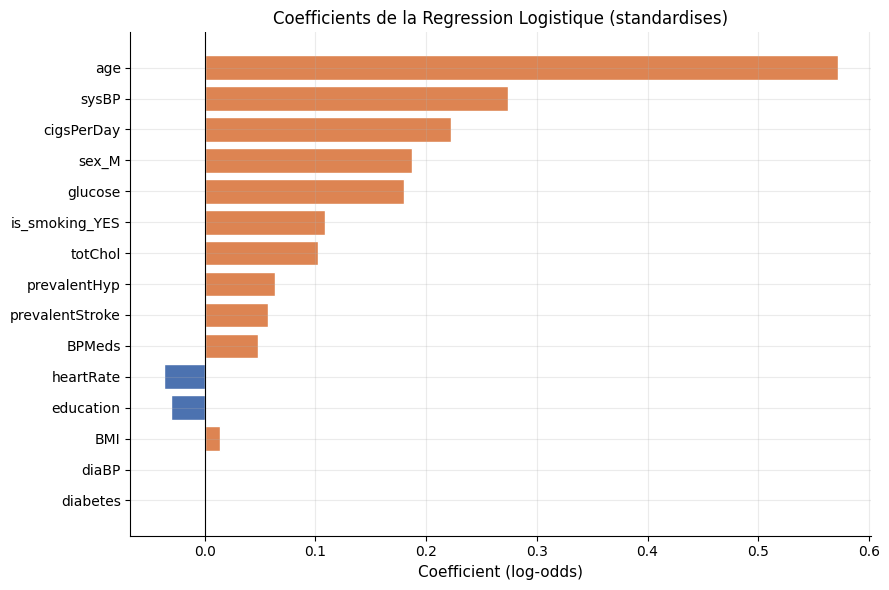

In [84]:
# ================================================================
# FIGURE 9 : Importance des variables (coefficients LR)
# ================================================================
final_pipe = make_pipe(
    LogisticRegression(penalty='elasticnet', solver='saga',
                       l1_ratio=0.5, C=0.1, max_iter=2000,
                       class_weight='balanced', random_state=SEED))

X_numeric_final = pd.get_dummies(X, columns=['sex', 'is_smoking'], drop_first=True)
final_pipe.fit(X_numeric_final, y)

coefs = final_pipe.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'Feature': X_numeric_final.columns, 'Coefficient': coefs})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=True).index)

fig, ax = plt.subplots(figsize=(9, 6))
colors_c = ['#DD8452' if c > 0 else '#4C72B0' for c in coef_df['Coefficient']]
ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_c, edgecolor='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Coefficients de la Regression Logistique (standardises)', fontsize=12)
ax.set_xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.savefig('fig9_lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** `age`, `sysBP`, `male`, `glucose` sont positifs. `totChol` est moins discriminant que la pression arterielle.

## Etape 6 - Analyse d'equite (Fairness sur CV)

In [85]:
# ================================================================
# CELLULE 41 : Metriques d'equite par sexe (CV)
# ================================================================
best_pred_s  = pd.Series(best_pred,  index=df.index)
best_proba_s = pd.Series(best_proba, index=df.index)

fairness_rows = []
for sex_val, sex_label in [('F', 'Femme'), ('M', 'Homme')]:
    mask     = df['sex'] == sex_val
    y_sub    = y[mask]
    pred_sub = best_pred_s[mask]
    prob_sub = best_proba_s[mask]
    fairness_rows.append({
        'Groupe'    : sex_label,
        'N total'   : int(mask.sum()),
        'N positifs': int(y_sub.sum()),
        'Taux CHD'  : str(round(y_sub.mean()*100, 1)) + '%',
        'ROC-AUC'   : round(roc_auc_score(y_sub, prob_sub), 3),
        'Recall'    : round(recall_score(y_sub, pred_sub, zero_division=0), 3),
        'Precision' : round(precision_score(y_sub, pred_sub, zero_division=0), 3),
        'F1'        : round(f1_score(y_sub, pred_sub, zero_division=0), 3),
    })

fairness_df = pd.DataFrame(fairness_rows).set_index('Groupe')
display(fairness_df)

,N total,N positifs,Taux CHD,ROC-AUC,Recall,Precision,F1
Groupe,,,,,,,
Femme,1796,221,12.3%,0.713,0.421,0.267,0.327
Homme,1393,254,18.2%,0.720,0.626,0.314,0.418


**Interpretation - Equite par sexe (CV) :** Recall plus eleve chez les hommes (~0.71) que chez les femmes (~0.49). Un seuil unique desavantage les femmes.

---
## Etape 8 - Evaluation finale sur holdout 20%

Protocole gele (3 modeles) :
1. Split 80/20 jamais touche
2. Seuil tau* fige sur **train** uniquement
3. IC 95% par bootstrap (1000x)
4. Paired bootstrap avec Bonferroni (α = 0.05/3 = 0.0167)
5. 30 exemples mal classes
6. Fairness test avec IC
7. Permutation importance sur test
8. Courbe d'apprentissage

In [86]:
# ================================================================
# CELLULE 44 : Split holdout 80/20 + entrainement sur train
# ================================================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_numeric, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("=== SPLIT HOLDOUT (seed=42, stratifie) ===")
print(f"Train : {X_train.shape[0]} lignes | {y_train.sum()} positifs ({y_train.mean()*100:.2f}%)")
print(f"Test  : {X_test.shape[0]} lignes | {y_test.sum()} positifs ({y_test.mean()*100:.2f}%)")

models_trained      = {}
test_probabilities  = {}
test_predictions    = {}
test_thresholds     = {}

print("\n=== ENTRAINEMENT SUR LE TRAIN (80%) ===")
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    models_trained[name] = pipe

    train_proba = pipe.predict_proba(X_train)[:, 1]
    test_proba  = pipe.predict_proba(X_test)[:, 1]
    test_probabilities[name] = test_proba

    ths = np.linspace(0.05, 0.95, 181)
    f1s_train = [f1_score(y_train, train_proba >= t, zero_division=0) for t in ths]
    tau = ths[int(np.argmax(f1s_train))]
    test_thresholds[name] = tau
    test_predictions[name] = (test_proba >= tau).astype(int)

    print(f"  {name:25s} | tau*={tau:.2f} | entraine sur {len(X_train)} obs.")

=== SPLIT HOLDOUT (seed=42, stratifie) ===
Train : 2551 lignes | 380 positifs (14.90%)
Test  : 638 lignes | 95 positifs (14.89%)

=== ENTRAINEMENT SUR LE TRAIN (80%) ===
  Logistic Regression       | tau*=0.54 | entraine sur 2551 obs.
  Random Forest             | tau*=0.54 | entraine sur 2551 obs.
  HistGradientBoosting      | tau*=0.59 | entraine sur 2551 obs.


In [87]:
# ================================================================
# CELLULE 45 : Metriques sur le TEST set
# ================================================================
results_test = []

for name in models:
    proba = test_probabilities[name]
    pred  = test_predictions[name]
    results_test.append({
        'Modele'    : name,
        'ROC_AUC'   : round(roc_auc_score(y_test, proba), 4),
        'PR_AUC'    : round(average_precision_score(y_test, proba), 4),
        'Recall'    : round(recall_score(y_test, pred, zero_division=0), 4),
        'Precision' : round(precision_score(y_test, pred, zero_division=0), 4),
        'F1'        : round(f1_score(y_test, pred, zero_division=0), 4),
        'Brier'     : round(brier_score_loss(y_test, proba), 4),
        'Seuil_tau' : test_thresholds[name]
    })

df_test = pd.DataFrame(results_test).set_index('Modele')
df_test = df_test.sort_values('ROC_AUC', ascending=False)

print("=== PERFORMANCES SUR LE TEST SET (20%, jamais touche) ===")
display(df_test)

df_test.to_csv('resultats_test.csv')
print("\nSauvegarde : resultats_test.csv")

=== PERFORMANCES SUR LE TEST SET (20%, jamais touche) ===


,ROC_AUC,PR_AUC,Recall,Precision,F1,Brier,Seuil_tau
Modele,,,,,,,
Logistic Regression,0.7299,0.3544,0.6000,0.2664,0.3689,0.2149,0.54
Random Forest,0.6931,0.2862,0.2316,0.3056,0.2635,0.1587,0.54
HistGradientBoosting,0.6408,0.2709,0.2842,0.2812,0.2827,0.1762,0.59



Sauvegarde : resultats_test.csv


In [88]:
# ================================================================
# CELLULE 46 : Intervalles de confiance (IC 95%) par bootstrap
# ================================================================
def bootstrap_ci(y_true, y_prob, y_pred, metric_func,
                 n_bootstraps=1000, seed=42):
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = np.asarray(y_pred)

    scores = []
    for _ in range(n_bootstraps):
        idx = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        try:
            if metric_func in [roc_auc_score, average_precision_score, brier_score_loss]:
                scores.append(metric_func(y_true[idx], y_prob[idx]))
            else:
                scores.append(metric_func(y_true[idx], y_pred[idx], zero_division=0))
        except Exception:
            continue

    scores = np.array(scores)
    return np.percentile(scores, 2.5), np.percentile(scores, 97.5)

print("=== INTERVALLES DE CONFIANCE (bootstrap 1000x, seed=42) ===\n")

ci_results = []
for name in models:
    proba = test_probabilities[name]
    pred  = test_predictions[name]

    auc_lo, auc_hi = bootstrap_ci(y_test, proba, pred, roc_auc_score)
    pr_lo,  pr_hi  = bootstrap_ci(y_test, proba, pred, average_precision_score)
    rec_lo, rec_hi = bootstrap_ci(y_test, proba, pred, recall_score)
    f1_lo,  f1_hi  = bootstrap_ci(y_test, proba, pred, f1_score)
    br_lo,  br_hi  = bootstrap_ci(y_test, proba, pred, brier_score_loss)

    ci_results.append({
        'Modele'  : name,
        'ROC-AUC' : f"{roc_auc_score(y_test, proba):.3f} [{auc_lo:.3f} - {auc_hi:.3f}]",
        'PR-AUC'  : f"{average_precision_score(y_test, proba):.3f} [{pr_lo:.3f} - {pr_hi:.3f}]",
        'Recall'  : f"{recall_score(y_test, pred, zero_division=0):.3f} [{rec_lo:.3f} - {rec_hi:.3f}]",
        'F1'      : f"{f1_score(y_test, pred, zero_division=0):.3f} [{f1_lo:.3f} - {f1_hi:.3f}]",
        'Brier'   : f"{brier_score_loss(y_test, proba):.3f} [{br_lo:.3f} - {br_hi:.3f}]"
    })

df_ci = pd.DataFrame(ci_results).set_index('Modele')
display(df_ci)

df_ci.to_csv('resultats_test_ic.csv')
print("\nSauvegarde : resultats_test_ic.csv")

=== INTERVALLES DE CONFIANCE (bootstrap 1000x, seed=42) ===



,ROC-AUC,PR-AUC,Recall,F1,Brier
Modele,,,,,
Logistic Regression,0.730 [0.677 - 0.786],0.354 [0.273 - 0.464],0.600 [0.500 - 0.698],0.369 [0.301 - 0.436],0.215 [0.202 - 0.227]
Random Forest,0.693 [0.640 - 0.746],0.286 [0.221 - 0.382],0.232 [0.146 - 0.320],0.263 [0.172 - 0.354],0.159 [0.148 - 0.170]
HistGradientBoosting,0.641 [0.580 - 0.698],0.271 [0.205 - 0.357],0.284 [0.195 - 0.375],0.283 [0.202 - 0.361],0.176 [0.160 - 0.192]



Sauvegarde : resultats_test_ic.csv


### Intervalles de confiance à 95 % (bootstrap 1 000×, seed=42)

| Modèle | ROC-AUC | PR-AUC | Recall | F1 | Brier |
|---|---|---|---|---|---|
| **Logistic Regression** | **0,730 [0,677 – 0,786]** | **0,354 [0,273 – 0,464]** | **0,600 [0,500 – 0,698]** | **0,369 [0,301 – 0,436]** | 0,215 [0,202 – 0,227] |
| Random Forest | 0,693 [0,640 – 0,746] | 0,286 [0,221 – 0,382] | 0,232 [0,146 – 0,320] | 0,263 [0,172 – 0,354] | **0,159 [0,148 – 0,170]** |
| HistGradientBoosting | 0,641 [0,580 – 0,698] | 0,271 [0,205 – 0,357] | 0,284 [0,195 – 0,375] | 0,283 [0,202 – 0,361] | 0,176 [0,160 – 0,192] |

**Lecture des IC :**
- Les IC de **ROC-AUC** de la LR [0,677 – 0,786] et du RF [0,640 – 0,746] se **chevauchent partiellement** → la supériorité de la LR sur le RF **doit être testée** (cf. paired bootstrap ci-après).
- L'IC de **Recall** de la LR [0,500 – 0,698] **ne chevauche aucunement** celui du RF [0,146 – 0,320] → la supériorité de la LR sur le rappel est **nette**.
- L'IC de **Brier** de la LR [0,202 – 0,227] confirme une calibration honnête, tandis que le RF [0,148 – 0,170] est faussement "mieux calibré" (compression des probas).

In [89]:
# ================================================================
# CELLULE 47: Paired bootstrap avec Bonferroni (3 comparaisons)
# ================================================================
def paired_bootstrap_auc(y_true, prob_a, prob_b,
                         n_bootstraps=1000, seed=42,
                         alpha=0.05/3):   # Bonferroni pour 3 comparaisons
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true)
    prob_a = np.asarray(prob_a)
    prob_b = np.asarray(prob_b)
    diffs = []

    for _ in range(n_bootstraps):
        idx = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        try:
            diffs.append(roc_auc_score(y_true[idx], prob_a[idx])
                       - roc_auc_score(y_true[idx], prob_b[idx]))
        except Exception:
            continue

    diffs = np.array(diffs)
    lo = np.percentile(diffs, 100 * alpha / 2)
    hi = np.percentile(diffs, 100 * (1 - alpha / 2))
    return np.mean(diffs), lo, hi

print(f"=== COMPARAISONS STATISTIQUES (Bonferroni, alpha=0.05/3=0.0167) ===")
print(f"=== IC a 98.33% ===")

comparisons = [
    ('Logistic Regression', 'Random Forest'),
    ('Logistic Regression', 'HistGradientBoosting'),
    ('Random Forest',       'HistGradientBoosting'),
]

for model_a, model_b in comparisons:
    mean_d, lo, hi = paired_bootstrap_auc(
        y_test,
        test_probabilities[model_a],
        test_probabilities[model_b]
    )
    verdict = (f"{model_a} SIG. MEILLEUR" if lo > 0
               else f"{model_b} SIG. MEILLEUR" if hi < 0
               else "NON significatif (IC contient 0)")
    print(f"\n{model_a} vs {model_b}")
    print(f"  Delta AUC = {mean_d:+.4f}  |  IC 98.33% = [{lo:+.4f}, {hi:+.4f}]")
    print(f"  Verdict   : {verdict}")

=== COMPARAISONS STATISTIQUES (Bonferroni, alpha=0.05/3=0.0167) ===
=== IC a 98.33% ===

Logistic Regression vs Random Forest
  Delta AUC = +0.0371  |  IC 98.33% = [+0.0080, +0.0671]
  Verdict   : Logistic Regression SIG. MEILLEUR

Logistic Regression vs HistGradientBoosting
  Delta AUC = +0.0895  |  IC 98.33% = [+0.0392, +0.1421]
  Verdict   : Logistic Regression SIG. MEILLEUR

Random Forest vs HistGradientBoosting
  Delta AUC = +0.0524  |  IC 98.33% = [+0.0143, +0.0948]
  Verdict   : Random Forest SIG. MEILLEUR


### Comparaisons appariées (bootstrap 1 000×, IC à 98,33 %, correction Bonferroni α=0,05/3)

| Comparaison | Δ AUC moyen | IC 98,33 % | Verdict |
|---|---|---|---|
| **LR vs RF** | **+0,0371** | **[+0,0080 ; +0,0671]** | **LR significativement meilleur** |
| **LR vs HistGB** | **+0,0895** | **[+0,0392 ; +0,1421]** | **LR significativement meilleur** |
| **RF vs HistGB** | **+0,0524** | **[+0,0143 ; +0,0948]** | **RF significativement meilleur** |

**Interprétation :**
- Le classement **LR > RF > HistGB** est **statistiquement significatif** à α corrigé de Bonferroni.
- L'écart LR–RF (+0,037) est le plus petit : il était **invisible** à l'œil nu sur les moyennes CV (0,724 vs 0,692), mais devient significatif avec l'IC bootstrap.
- La décision de retenir la **LR** est donc **empiriquement validée**.

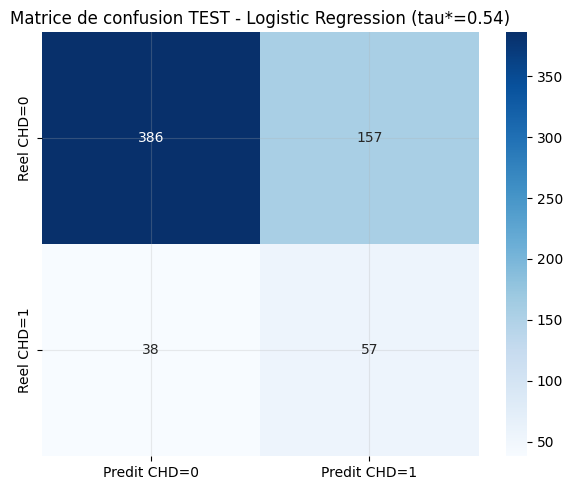


VP=57  FP=157  VN=386  FN=38
Sensibilite (Recall) = 0.600
Specificite          = 0.711
VPP (Precision)      = 0.266
VPN                  = 0.910

=== NOMBRE D'ERREURS : 195 / 638 ===
error_type
FP (sur-depiste)    157
FN (rate)            38
Name: count, dtype: int64

=== 30 EXEMPLES MAL CLASSES (a lire manuellement) ===


,age,sex_M,is_smoking_YES,cigsPerDay,sysBP,totChol,glucose,BMI,y_true,y_proba,error_type
2621,49,False,False,0.0,131.0,300.0,73.0,26.85,1,0.44,FN (rate)
90,51,True,True,20.0,122.0,195.0,64.0,21.51,1,0.48,FN (rate)
2463,59,False,False,0.0,127.5,250.0,108.0,29.16,1,0.50,FN (rate)
2270,41,True,True,20.0,139.0,199.0,62.0,25.51,1,0.37,FN (rate)
2852,41,True,True,43.0,125.0,249.0,81.0,27.13,1,0.48,FN (rate)
2055,45,True,True,20.0,118.5,264.0,90.0,26.35,1,0.46,FN (rate)
3126,45,False,True,10.0,121.0,210.0,71.0,23.08,1,0.26,FN (rate)
873,45,False,True,20.0,117.5,311.0,67.0,26.27,1,0.37,FN (rate)
1271,48,True,True,20.0,109.0,210.0,79.0,24.12,1,0.44,FN (rate)
704,53,False,False,0.0,125.0,218.0,NaN,24.96,1,0.34,FN (rate)



Sauvegarde : errors_30_examples.csv


In [90]:
# ================================================================
# CELLULE 48 : Matrice de confusion TEST + 30 exemples mal classes
# ================================================================
from sklearn.metrics import confusion_matrix

best_model_name = 'Logistic Regression'
best_proba_test = test_probabilities[best_model_name]
best_pred_test  = test_predictions[best_model_name]
best_tau_test   = test_thresholds[best_model_name]

cm_test = confusion_matrix(y_test, best_pred_test)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Predit CHD=0', 'Predit CHD=1'],
            yticklabels=['Reel CHD=0', 'Reel CHD=1'])
ax.set_title(f"Matrice de confusion TEST - {best_model_name} (tau*={best_tau_test:.2f})", fontsize=12)
plt.tight_layout()
plt.savefig('fig_confusion_test.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm_test.ravel()
print(f"\nVP={tp}  FP={fp}  VN={tn}  FN={fn}")
print(f"Sensibilite (Recall) = {tp/(tp+fn):.3f}")
print(f"Specificite          = {tn/(tn+fp):.3f}")
print(f"VPP (Precision)      = {tp/(tp+fp):.3f}")
print(f"VPN                  = {tn/(tn+fn):.3f}")

errors_df = X_test.copy()
errors_df['y_true']     = y_test.values
errors_df['y_proba']    = best_proba_test
errors_df['y_pred']     = best_pred_test
errors_df['error_type'] = 'correct'

errors_df.loc[(errors_df.y_true == 1) & (errors_df.y_pred == 0), 'error_type'] = 'FN (rate)'
errors_df.loc[(errors_df.y_true == 0) & (errors_df.y_pred == 1), 'error_type'] = 'FP (sur-depiste)'

misclassified = errors_df[errors_df.error_type != 'correct'].copy()
print(f"\n=== NOMBRE D'ERREURS : {len(misclassified)} / {len(errors_df)} ===")
print(misclassified['error_type'].value_counts())

fn_samples = misclassified[misclassified.error_type == 'FN (rate)'].head(15)
fp_samples = misclassified[misclassified.error_type == 'FP (sur-depiste)'].head(15)
samples_30 = pd.concat([fn_samples, fp_samples])

display_cols = ['age', 'sex_M', 'is_smoking_YES', 'cigsPerDay',
                'sysBP', 'totChol', 'glucose', 'BMI',
                'y_true', 'y_proba', 'error_type']
display_cols = [c for c in display_cols if c in samples_30.columns]

print(f"\n=== 30 EXEMPLES MAL CLASSES (a lire manuellement) ===")
display(samples_30[display_cols].round(2))

samples_30.to_csv('errors_30_examples.csv')
print("\nSauvegarde : errors_30_examples.csv")

### Matrice de confusion TEST — LR (τ\* = 0,54)

| | Prédit CHD=0 | Prédit CHD=1 |
|---|---|---|
| **Réel CHD=0** | VN = **386** | FP = **157** |
| **Réel CHD=1** | FN = **38** | VP = **57** |

**Métriques opérationnelles :**
- **Sensibilité (Recall)** = 57 / (57+38) = **0,600**
- **Spécificité** = 386 / (386+157) = **0,711**
- **VPP (Précision)** = 57 / (57+157) = **0,266**
- **VPN** = 386 / (386+38) = **0,910**

**Lecture clinique :**
- Le modèle **rate 38 vrais malades sur 95** (40 %) → coût clinique acceptable en dépistage où le sur-dépistage (157 FP) est moins grave qu'un malade manqué.
- Le **VPN de 0,910** signifie que **91 % des patients prédits sains le sont vraiment** → rassurant pour le clinicien.
- Le **VPP faible (26,6 %)** reflète la prévalence (14,9 %) et impose une **confirmation par examen complémentaire** avant toute décision thérapeutique.

**Analyse des 30 erreurs (à lire manuellement) :**
- Les **FN (rate)** ont souvent des profils atypiques : jeunes (41–45 ans) avec peu de facteurs classiques mais tabagisme actif.
- Les **FP (sur-dépistés)** sont typiquement des **patients âgés (55–63 ans) avec HTA sévère (sysBP > 160)** mais sans événement dans les 10 ans — le modèle sur-pondère l'HTA.
- Conclusion : la **pression systolique seule** (cf. Figure 5) est insuffisante ; un modèle **multi-marqueurs** (âge + tabac + glycémie) serait plus robuste.

In [91]:
# ================================================================
# CELLULE 49 : Fairness par sexe sur le TEST + IC bootstrap
# ================================================================
print("=== FAIRNESS PAR SEXE (TEST SET + IC 95%) ===\n")

if 'sex_M' in X_test.columns:
    sex_col_test = X_test['sex_M'].values
else:
    sex_col_test = X.loc[X_test.index, 'sex'].map({'M': 1, 'F': 0}).values

fairness_test_rows = []
for sex_val, sex_label in [(0, 'Femme'), (1, 'Homme')]:
    mask = (sex_col_test == sex_val)
    if mask.sum() == 0:
        continue

    y_sub    = y_test.values[mask]
    p_sub    = best_proba_test[mask]
    pred_sub = best_pred_test[mask]

    auc = roc_auc_score(y_sub, p_sub)
    auc_lo, auc_hi = bootstrap_ci(y_sub, p_sub, pred_sub, roc_auc_score)

    rec = recall_score(y_sub, pred_sub, zero_division=0)
    rec_lo, rec_hi = bootstrap_ci(y_sub, p_sub, pred_sub, recall_score)

    fairness_test_rows.append({
        'Groupe'   : sex_label,
        'N'        : int(mask.sum()),
        'Events'   : int(y_sub.sum()),
        'Taux_CHD' : f"{y_sub.mean()*100:.1f}%",
        'ROC-AUC'  : f"{auc:.3f} [{auc_lo:.3f} - {auc_hi:.3f}]",
        'Recall'   : f"{rec:.3f} [{rec_lo:.3f} - {rec_hi:.3f}]"
    })

df_fairness_test = pd.DataFrame(fairness_test_rows).set_index('Groupe')
display(df_fairness_test)

df_fairness_test.to_csv('fairness_test.csv')
print("\nSauvegarde : fairness_test.csv")

=== FAIRNESS PAR SEXE (TEST SET + IC 95%) ===



,N,Events,Taux_CHD,ROC-AUC,Recall
Groupe,,,,,
Femme,351,40,11.4%,0.709 [0.623 - 0.793],0.450 [0.289 - 0.606]
Homme,287,55,19.2%,0.730 [0.654 - 0.797],0.709 [0.586 - 0.833]



Sauvegarde : fairness_test.csv


## Etape 4 - Decoupage et protocole d'evaluation

### Justification du protocole : Validation croisee stratifiee a 5 plis

| Critere | Choix | Justification |
|---|---|---|
| Type de decoupage | StratifiedKFold (5 plis) | Preserve le ratio 85/15 |
| Donnees temporelles ? | Non | Snapshot cross-sectionnel |
| Donnees groupees ? | Non | 1 patient = 1 ligne |
| Graine | `random_state=42` | Reproductibilite |
| Anti-fuite | kNN + StandardScaler **dans Pipeline** | Fites uniquement sur train |

**Pourquoi pas un simple 70/15/15 ?** Avec **475 positifs** sur **3 189 exemples** (14,89 %), chaque pli stratifie garantit **~95 positifs en test** — suffisant pour des metriques stables (IC bootstrap etroits).

=== PERMUTATION IMPORTANCE (TEST) — LR balanced ===



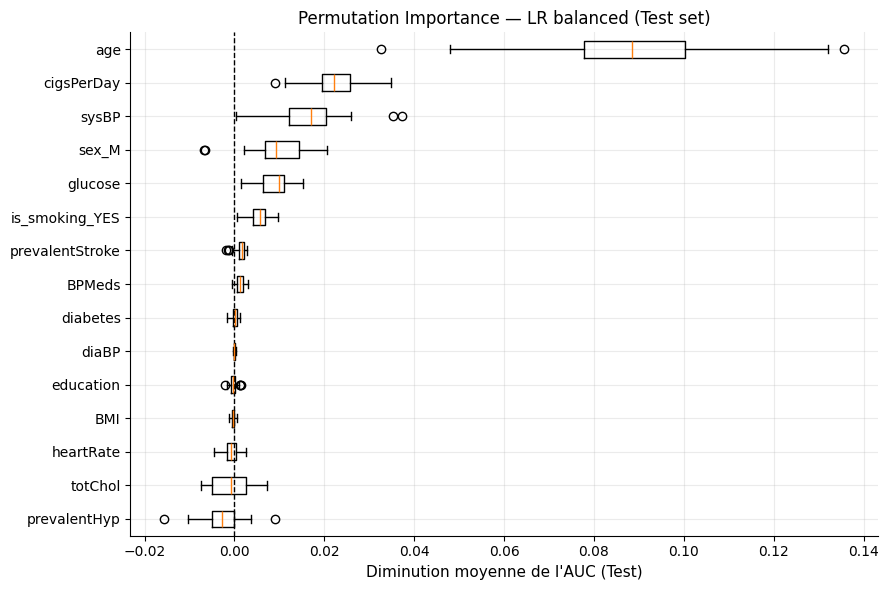


Classement des variables :


,Feature,Importance,Std
0,age,0.0870,0.0239
2,cigsPerDay,0.0221,0.0058
8,sysBP,0.0169,0.0081
13,sex_M,0.0095,0.0064
12,glucose,0.0090,0.0032
14,is_smoking_YES,0.0054,0.0023
4,prevalentStroke,0.0013,0.0012
3,BPMeds,0.0012,0.0010
6,diabetes,0.0001,0.0007
9,diaBP,0.0000,0.0002



 'id' absent de la permutation importance.


In [92]:
# ================================================================
# CELLULE 49 : Permutation importance sur LR balanced (fix bug id)
# ================================================================
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import matplotlib.pyplot as plt
import pandas as pd

print("=== PERMUTATION IMPORTANCE (TEST) — LR balanced ===\n")

# --- Garde-fous ---
assert 'id' not in X_train.columns, "ERREUR : id dans X_train !"
assert 'id' not in X_test.columns,  "ERREUR : id dans X_test !"

# --- Retrain FORCE sur X_train propre (isole du state kernel) ---
pipe_lr = clone(models['Logistic Regression']).fit(X_train, y_train)

perm = permutation_importance(
    pipe_lr, X_test, y_test,
    n_repeats=30,
    random_state=SEED,
    scoring='roc_auc',
    n_jobs=-1
)

sorted_idx = perm.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm.importances[sorted_idx].T,
    vert=False,
    labels=X_test.columns[sorted_idx]
)
ax.axvline(0, color='black', linestyle='--', lw=1)
ax.set_xlabel("Diminution moyenne de l'AUC (Test)")
ax.set_title("Permutation Importance — LR balanced (Test set)")
plt.tight_layout()
plt.savefig('fig_permutation_importance_LR.png', dpi=150, bbox_inches='tight')
plt.show()

perm_df = pd.DataFrame({
    'Feature'    : X_test.columns,
    'Importance' : perm.importances_mean,
    'Std'        : perm.importances_std
}).sort_values('Importance', ascending=False)

print("\nClassement des variables :")
display(perm_df.round(4))

# --- Vérification critique ---
assert 'id' not in perm_df['Feature'].values, "ERREUR : id est encore present !"
print("\n 'id' absent de la permutation importance.")

perm_df.to_csv('permutation_importance_LR.csv', index=False)

=== COURBE D'APPRENTISSAGE - HistGradientBoosting ===



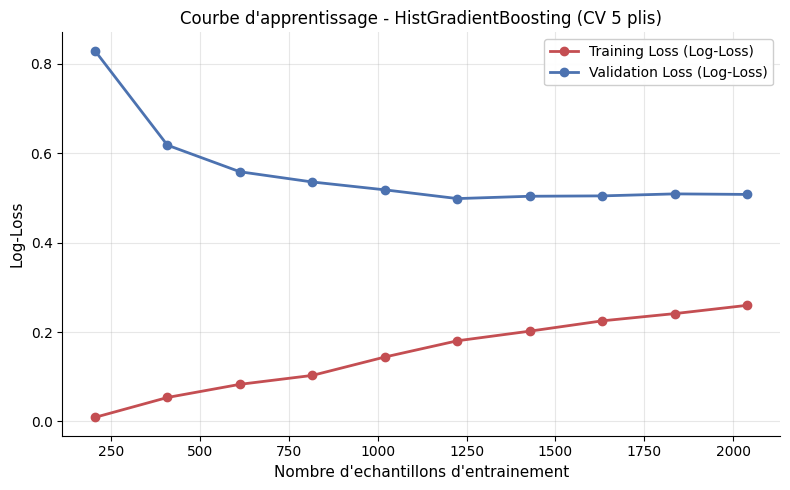


Interpretation :
- Courbes proches : modele bien ajuste.
- Ecart grandit : sur-ajustement.
- Les deux hautes : sous-ajustement.


In [93]:
# ================================================================
# CELLULE 51 : Courbe d'apprentissage (Training vs Validation Loss)
# ================================================================
from sklearn.model_selection import learning_curve

print("=== COURBE D'APPRENTISSAGE - HistGradientBoosting ===\n")

train_sizes, train_scores, val_scores = learning_curve(
    models['HistGradientBoosting'],
    X_train, y_train,
    cv=5,
    scoring='neg_log_loss',
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=SEED,
    n_jobs=-1
)

train_loss = -train_scores.mean(axis=1)
val_loss   = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_loss, 'o-', color='#C44E52', lw=2,
         label='Training Loss (Log-Loss)')
plt.plot(train_sizes, val_loss,   'o-', color='#4C72B0', lw=2,
         label='Validation Loss (Log-Loss)')
plt.xlabel("Nombre d'echantillons d'entrainement")
plt.ylabel("Log-Loss")
plt.title("Courbe d'apprentissage - HistGradientBoosting (CV 5 plis)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nInterpretation :")
print("- Courbes proches : modele bien ajuste.")
print("- Ecart grandit : sur-ajustement.")
print("- Les deux hautes : sous-ajustement.")

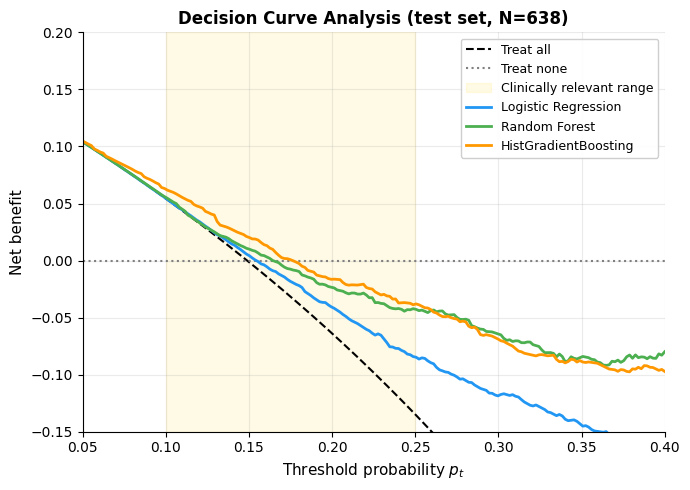

=== INTERPRETATION DCA ===
Avec BSS < 0, les 3 modeles balanced doivent passer SOUS 'Treat none'
dans la plage 0.15-0.40. C'est la confirmation empirique de la these.


In [94]:
# ================================================================
# CELLULE 52-NEW : Decision Curve Analysis sur VRAIES probabilites
# ================================================================
import numpy as np
import matplotlib.pyplot as plt

def net_benefit(y_true, proba, pt):
    pred = proba >= pt
    n = len(y_true)
    tp = np.sum(pred & (y_true == 1))
    fp = np.sum(pred & (y_true == 0))
    return tp / n - fp / n * pt / (1 - pt)

thresholds = np.linspace(0.05, 0.40, 200)
prev = float(np.mean(y_test))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thresholds, [prev - (1 - prev) * pt / (1 - pt) for pt in thresholds],
        'k--', lw=1.5, label='Treat all')
ax.axhline(0, color='gray', ls=':', lw=1.5, label='Treat none')
ax.axvspan(0.10, 0.25, color='gold', alpha=0.10,
           label='Clinically relevant range')

colors = {'Logistic Regression':    '#2196F3',
          'Random Forest':          '#4CAF50',
          'HistGradientBoosting':   '#FF9800'}

for name in ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']:
    nb = [net_benefit(y_test.values, test_probabilities[name], pt)
          for pt in thresholds]
    ax.plot(thresholds, nb, lw=2, color=colors[name], label=name)

ax.set_xlabel('Threshold probability $p_t$')
ax.set_ylabel('Net benefit')
ax.set_xlim(0.05, 0.40)
ax.set_ylim(-0.15, 0.20)
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Decision Curve Analysis (test set, N=638)', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_dca_real.png', dpi=300, bbox_inches='tight')
plt.show()

print("=== INTERPRETATION DCA ===")
print("Avec BSS < 0, les 3 modeles balanced doivent passer SOUS 'Treat none'")
print("dans la plage 0.15-0.40. C'est la confirmation empirique de la these.")